In [2]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# 1. Robustly locate the project root
project_root = Path.cwd()
while not (project_root / "data" / "processed").is_dir():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent

# 2. Define the path to the clean Parquet file
parquet_path = project_root / "data" / "processed" / "fact_trips_clean.parquet"

if not parquet_path.is_file():
    raise FileNotFoundError(f"Cleaned Parquet file not found: {parquet_path}")

# 3. Load the data
df = pl.read_parquet(parquet_path)
print(f"✅ Successfully loaded {len(df):,} cleaned rows.")

✅ Successfully loaded 20,545,565 cleaned rows.


In [3]:
# Create a unified "trip_route" string for easy grouping
# Example: "Central Park West & W 76 St -> W 89 St & Columbus Ave"
df_routes = df.with_columns(
    (pl.col("start_station_name") + " ➔ " + pl.col("end_station_name")).alias("trip_route")
)

print("✅ Created 'trip_route' feature.")

✅ Created 'trip_route' feature.


In [4]:
# Aggregate trip counts by user type and route
route_counts = (
    df_routes.group_by(["user_type", "trip_route"])
    .agg(pl.len().alias("trip_count"))
)

# Get Top 10 for Subscribers
top_subscribers = (
    route_counts.filter(pl.col("user_type") == "Subscriber")
    .sort("trip_count", descending=True)
    .head(10)
)

# Get Top 10 for Customers
top_customers = (
    route_counts.filter(pl.col("user_type") == "Customer")
    .sort("trip_count", descending=True)
    .head(10)
)

print("=== TOP 10 MOST FREQUENT TRIPS: SUBSCRIBERS ===")
print(top_subscribers)

print("\n=== TOP 10 MOST FREQUENT TRIPS: CUSTOMERS ===")
print(top_customers)

=== TOP 10 MOST FREQUENT TRIPS: SUBSCRIBERS ===
shape: (10, 3)
┌────────────┬─────────────────────────────────┬────────────┐
│ user_type  ┆ trip_route                      ┆ trip_count │
│ ---        ┆ ---                             ┆ ---        │
│ str        ┆ str                             ┆ u32        │
╞════════════╪═════════════════════════════════╪════════════╡
│ Subscriber ┆ E 7 St & Avenue A ➔ Cooper Squ… ┆ 8116       │
│ Subscriber ┆ North Moore St & Greenwich St … ┆ 5214       │
│ Subscriber ┆ Vesey Pl & River Terrace ➔ Nor… ┆ 5071       │
│ Subscriber ┆ Pershing Square North ➔ E 24 S… ┆ 4892       │
│ Subscriber ┆ E 13 St & Avenue A ➔ Broadway … ┆ 4732       │
│ Subscriber ┆ Pershing Square North ➔ W 33 S… ┆ 4731       │
│ Subscriber ┆ McGuinness Blvd & Eagle St ➔ V… ┆ 4719       │
│ Subscriber ┆ Vernon Blvd & 50 Ave ➔ McGuinn… ┆ 4552       │
│ Subscriber ┆ W 22 St & 10 Ave ➔ W 22 St & 8… ┆ 4536       │
│ Subscriber ┆ E 6 St & Avenue B ➔ Cooper Squ… ┆ 4494       │
└──────

C:\Users\George\AppData\Local\Temp\ipykernel_21976\706710168.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub_df, x="trip_count", y="trip_route", ax=ax1, palette="Blues_r")
C:\Users\George\AppData\Local\Temp\ipykernel_21976\706710168.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cust_df, x="trip_count", y="trip_route", ax=ax2, palette="Oranges_r")
C:\Users\George\AppData\Local\Temp\ipykernel_21976\706710168.py:22: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  plt.tight_layout()
d:\henkel-citibike-task\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARR

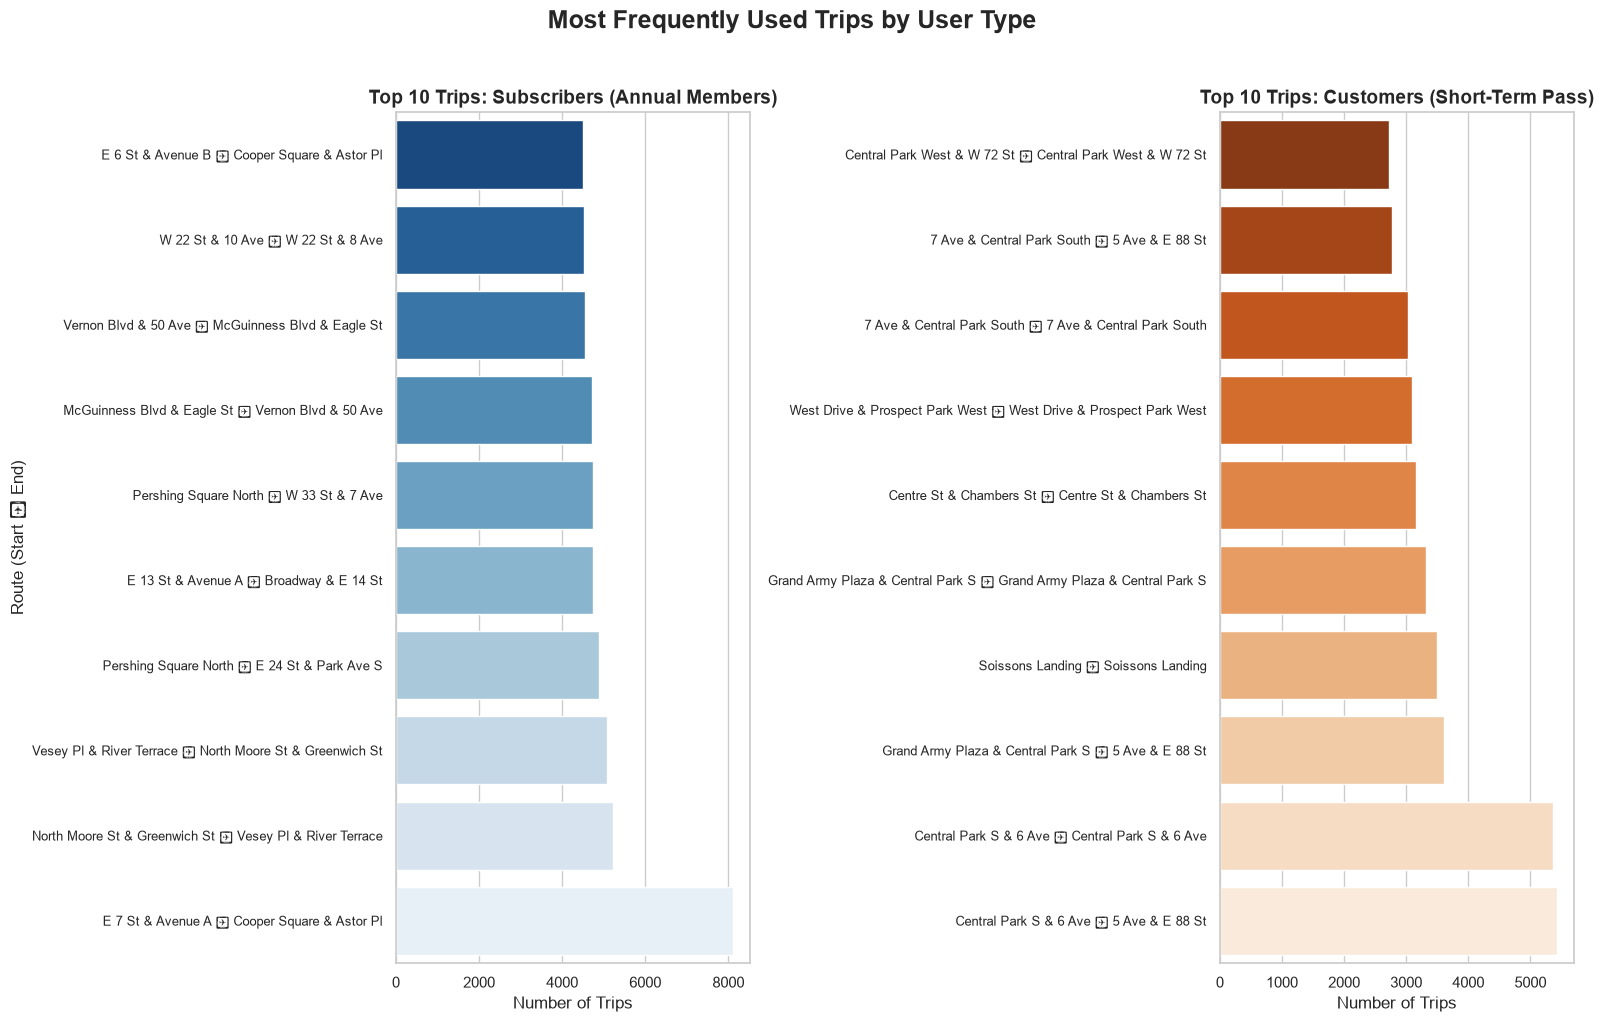

In [5]:
# Convert to pandas for easier plotting with seaborn/matplotlib
sub_df = top_subscribers.sort("trip_count", descending=False).to_pandas() # Sort ascending for horizontal bar chart
cust_df = top_customers.sort("trip_count", descending=False).to_pandas()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10))

# Plot Subscribers
sns.barplot(data=sub_df, x="trip_count", y="trip_route", ax=ax1, palette="Blues_r")
ax1.set_title("Top 10 Trips: Subscribers (Annual Members)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Number of Trips")
ax1.set_ylabel("Route (Start ➔ End)")
ax1.tick_params(axis='y', labelsize=9) # Smaller font for long route names

# Plot Customers
sns.barplot(data=cust_df, x="trip_count", y="trip_route", ax=ax2, palette="Oranges_r")
ax2.set_title("Top 10 Trips: Customers (Short-Term Pass)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Number of Trips")
ax2.set_ylabel("") # Remove duplicate y-axis label
ax2.tick_params(axis='y', labelsize=9)

plt.suptitle("Most Frequently Used Trips by User Type", fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Answer to Question 3

**1. What are the most frequently used trips?**
The most frequent trips are highly concentrated, but the nature of these routes differs drastically between user types. 

**2. Are they different for subscribers and customers?**
**Yes, there is a stark contrast in behavior that perfectly aligns with Commuters vs. Tourists:**

*   **Subscribers (Commuters):** Their top trips have very high volumes (4,400 to 8,100+ trips). The routes connect dense residential neighborhoods (e.g., East Village's *Avenue A/B*, *Vernon Blvd* in Brooklyn) directly to major transit and commercial hubs (e.g., *Cooper Square*, *Pershing Square*, *W 33 St*). 
*   **Customers (Tourists/Leisure):** Their top trips have lower maximum volumes (2,700 to 5,400 trips) and are heavily clustered around iconic recreational areas: *Central Park South*, *Grand Army Plaza*, *Prospect Park West*, and *Soissons Landing* (the ferry terminal to Governors Island). 
*   **The "Smoking Gun" Insight:** The Customer top 10 includes *"Soissons Landing ➔ Soissons Landing"*. This indicates a user rented a bike, rode a loop (likely around Governors Island), and returned it to the exact same dock. This "round-trip" leisure behavior is almost entirely absent from the Subscriber top 10.

**Business Recommendation:** 
Station rebalancing (moving bikes from full docks to empty docks) must be optimized differently for these groups:
1. **For Subscribers:** Focus on directional, tidal flows during morning (7-9 AM) and evening (5-7 PM) rush hours between residential zones and business/transit hubs.
2. **For Customers:** Focus on maintaining high bike availability around major tourist landmarks (Central Park, Prospect Park) throughout the entire day and on weekends, and ensure docks at these locations have enough empty slots to accept the high volume of "loop" returns.